[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Spatial Joins &middot; Solutions


One way to do each task. Not the only way. If yours runs and does what was asked, yours is
right too.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)

named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "|", len(stations), "made-up stations,", len(named), "named stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | 300 made-up stations, 5 named stations, 8 made-up districts


The worked examples' joined table, rebuilt here so that each answer runs on its own. The stations and the districts are made up.

In [2]:
stations_m = stations.to_crs(districts.crs)
joined = gpd.sjoin(stations_m, districts)

**1.** Join the network stations to the districts and print how many stations each `owner` has in the North district.

In [3]:
joined[joined["district"] == "North"].groupby("owner").size()

owner
airport     2
met         6
private     8
road       11
dtype: int64

The join gives every station its district, and the filter keeps the North district's 27 before `groupby` counts them by owner.

**2.** Print every district's count of stations installed in 2000 or later, with Svalbard shown as 0.

In [4]:
recent = joined[joined["installed"] >= 2000]
recent.groupby("district").size().reindex(districts["district"], fill_value=0)

district
South        11
East         20
West         16
Mid          24
North        16
Far North     7
Northeast    25
Svalbard      0
dtype: int64

Filtering before counting leaves out districts with no recent stations, so `reindex` puts them back with 0, in the districts' own order.

**3.** Join the five named stations to `countries` with a left join, and print each station's country, with `NaN` where it has none.

In [5]:
gpd.sjoin(named, countries[["ADMIN", "geometry"]], how="left")[["name", "ADMIN"]]

,name,ADMIN
0,Bergen,Norway
1,Oslo,Norway
2,Svalbard,Norway
3,Tromso,NaN
4,Kirkenes,NaN


Both tables are in degrees, so no conversion is needed. Tromso and Kirkenes stand just outside the 1:50m coastline, and the left join keeps them with `NaN`.

**4.** Add a column `airport_share` to a copy of the districts, the share of each district's stations whose owner is `airport`, with Svalbard left as `NaN`, and print it rounded to two places.

In [6]:
share = (joined["owner"] == "airport").groupby(joined["district"]).mean()
with_share = districts.assign(airport_share=share.reindex(districts["district"]).to_numpy())
with_share[["district", "airport_share"]].round(2)

,district,airport_share
0,South,0.03
1,East,0.14
2,West,0.14
3,Mid,0.12
4,North,0.07
5,Far North,0.08
6,Northeast,0.12
7,Svalbard,NaN


The mean of a column of `True` and `False` is the share that is `True`. Svalbard has no stations, so `reindex` leaves its share as `NaN`, which is what a share of nothing should be.

**5.** Draw a map of the districts colored by their mean station elevation, with the stations on top.

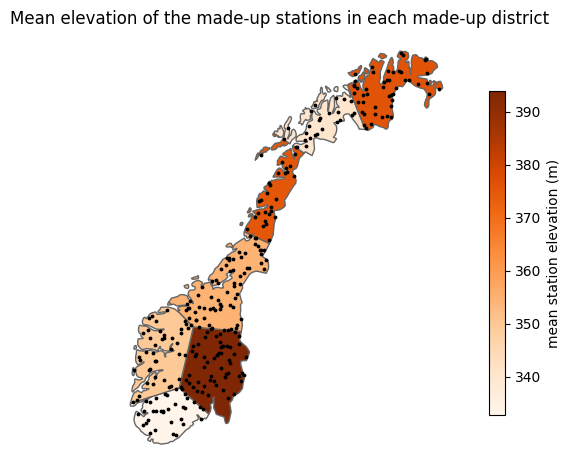

In [7]:
mean_elevation = joined.groupby("district")["elevation_m"].mean()
shaded = districts.assign(mean_elevation_m=mean_elevation.reindex(districts["district"]).to_numpy())
fig, ax = plt.subplots(figsize=(6, 7))
shaded.plot(ax=ax, column="mean_elevation_m", cmap="Oranges", edgecolor="0.4", legend=True,
            legend_kwds={"label": "mean station elevation (m)", "shrink": 0.6})
stations_m.plot(ax=ax, color="black", markersize=3)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Mean elevation of the made-up stations in each made-up district")
plt.show()

`plot` leaves out a district with no value, and the limits keep Svalbard off the map in any case. The elevations are made up and do not follow the land.

---

&#8592; **Back to:** [Spatial Joins](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/08-spatial-joins.ipynb)  &nbsp;&middot;&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
